### Import Libraries

In [18]:
# Import numerical and data manipulation libraries
import numpy as np
import pandas as pd

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning tools from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

### Read Data set

In [19]:
# Read csv using Pandas
dataset = pd.read_csv('Data_electric_vehicles.csv')

### View Data set

In [20]:
# Display the first 5 rows to understand the structure
dataset.head()

,brand,top_speed_kmh,battery_capacity_kWh,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,towing_capacity_kg,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,cargo_volume_l_num
0,Abarth,155,37.8,235.0,156,225,7.0,67.0,0.0,4,FWD,B - Compact,3673,1683,1518,Hatchback,185.0
1,Abarth,155,37.8,235.0,149,225,7.0,67.0,0.0,4,FWD,B - Compact,3673,1683,1518,Hatchback,185.0
2,Abarth,200,50.8,345.0,158,280,5.9,79.0,0.0,5,FWD,JB - Compact,4187,1779,1557,SUV,360.0
3,Abarth,200,50.8,345.0,158,280,6.2,79.0,0.0,5,FWD,JB - Compact,4187,1779,1557,SUV,360.0
4,Aiways,150,60.0,310.0,156,315,7.5,78.0,NaN,5,FWD,JC - Medium,4680,1865,1700,SUV,496.0


### View information about the dataset

In [21]:
# Display basic information about the dataset
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand                      478 non-null    str    
 1   top_speed_kmh              478 non-null    int64  
 2   battery_capacity_kWh       478 non-null    float64
 3   torque_nm                  471 non-null    float64
 4   efficiency_wh_per_km       478 non-null    int64  
 5   range_km                   478 non-null    int64  
 6   acceleration_0_100_s       478 non-null    float64
 7   fast_charging_power_kw_dc  477 non-null    float64
 8   towing_capacity_kg         452 non-null    float64
 9   seats                      478 non-null    int64  
 10  drivetrain                 478 non-null    str    
 11  segment                    478 non-null    str    
 12  length_mm                  478 non-null    int64  
 13  width_mm                   478 non-null    int64  
 14  heigh

### Data processing

In [23]:
# Display the initial shape of the dataset
dataset.shape

(478, 17)

### Checking missing values

In [24]:
# Check for missing values
dataset.isna().sum()

brand                         0
top_speed_kmh                 0
battery_capacity_kWh          0
torque_nm                     7
efficiency_wh_per_km          0
range_km                      0
acceleration_0_100_s          0
fast_charging_power_kw_dc     1
towing_capacity_kg           26
seats                         0
drivetrain                    0
segment                       0
length_mm                     0
width_mm                      0
height_mm                     0
car_body_type                 0
cargo_volume_l_num            1
dtype: int64

### check the percentage of missing values

In [25]:
missing = dataset.isna().sum()
missing_pct = (dataset.isna().mean() * 100).round(2)

pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct
}).sort_values("missing_count", ascending=False)


,missing_count,missing_percent
towing_capacity_kg,26,5.44
torque_nm,7,1.46
fast_charging_power_kw_dc,1,0.21
cargo_volume_l_num,1,0.21
brand,0,0.00
efficiency_wh_per_km,0,0.00
battery_capacity_kWh,0,0.00
acceleration_0_100_s,0,0.00
top_speed_kmh,0,0.00
range_km,0,0.00


### Cleaning dataset

In [28]:
cols_to_fill = [
    'torque_nm',
    'fast_charging_power_kw_dc',
    'towing_capacity_kg',
    'cargo_volume_l_num'
]

for col in cols_to_fill:
    dataset[col] = dataset[col].fillna(dataset[col].median())

In [29]:
# Check for missing values
dataset.isna().sum()

brand                        0
top_speed_kmh                0
battery_capacity_kWh         0
torque_nm                    0
efficiency_wh_per_km         0
range_km                     0
acceleration_0_100_s         0
fast_charging_power_kw_dc    0
towing_capacity_kg           0
seats                        0
drivetrain                   0
segment                      0
length_mm                    0
width_mm                     0
height_mm                    0
car_body_type                0
cargo_volume_l_num           0
dtype: int64

In [30]:
# Remove duplicate rows if any
dataset.drop_duplicates()

,brand,top_speed_kmh,battery_capacity_kWh,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,towing_capacity_kg,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,cargo_volume_l_num
0,Abarth,155,37.8,235.0,156,225,7.0,67.0,0.0,4,FWD,B - Compact,3673,1683,1518,Hatchback,185.0
1,Abarth,155,37.8,235.0,149,225,7.0,67.0,0.0,4,FWD,B - Compact,3673,1683,1518,Hatchback,185.0
2,Abarth,200,50.8,345.0,158,280,5.9,79.0,0.0,5,FWD,JB - Compact,4187,1779,1557,SUV,360.0
3,Abarth,200,50.8,345.0,158,280,6.2,79.0,0.0,5,FWD,JB - Compact,4187,1779,1557,SUV,360.0
4,Aiways,150,60.0,310.0,156,315,7.5,78.0,1000.0,5,FWD,JC - Medium,4680,1865,1700,SUV,496.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
473,Zeekr,210,71.0,440.0,148,365,6.0,240.0,2000.0,5,RWD,JD - Large,4787,1930,1650,SUV,539.0
474,Zeekr,190,49.0,343.0,148,265,5.9,70.0,1600.0,5,RWD,JB - Compact,4432,1836,1566,SUV,362.0
475,Zeekr,190,65.0,343.0,146,360,5.6,114.0,1600.0,5,RWD,JB - Compact,4432,1836,1566,SUV,362.0
476,Zeekr,190,65.0,543.0,153,350,3.8,114.0,1600.0,5,AWD,JB - Compact,4432,1836,1566,SUV,362.0


In [31]:
# Show shape after removing duplicates
print(f"Shape after removing duplicates: {dataset.shape}")

Shape after removing duplicates: (478, 17)


In [73]:
categorical_cols = ['brand', 'drivetrain', 'segment', 'car_body_type']

label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    dataset[col] = le.fit_transform(dataset[col])
    label_encoders[col] = le

In [34]:
# Display the first few rows of the cleaned dataset
print("First few rows of the cleaned dataset:")
print(dataset.head())

First few rows of the cleaned dataset:
   brand  top_speed_kmh  battery_capacity_kWh  torque_nm  \
0      0            155                  37.8      235.0   
1      0            155                  37.8      235.0   
2      0            200                  50.8      345.0   
3      0            200                  50.8      345.0   
4      1            150                  60.0      310.0   

   efficiency_wh_per_km  range_km  acceleration_0_100_s  \
0                   156       225                   7.0   
1                   149       225                   7.0   
2                   158       280                   5.9   
3                   158       280                   6.2   
4                   156       315                   7.5   

   fast_charging_power_kw_dc  towing_capacity_kg  seats  drivetrain  segment  \
0                       67.0                 0.0      4           1        1   
1                       67.0                 0.0      4           1        1   
2    

### Exploratory Data Analysis (EDA)

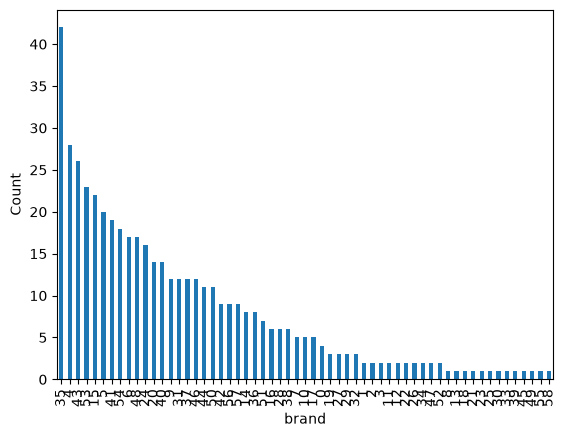

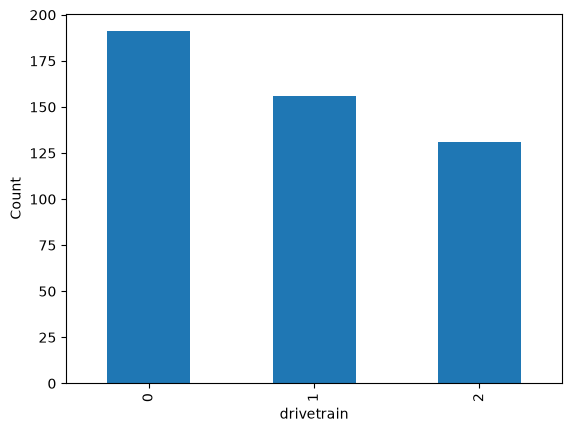

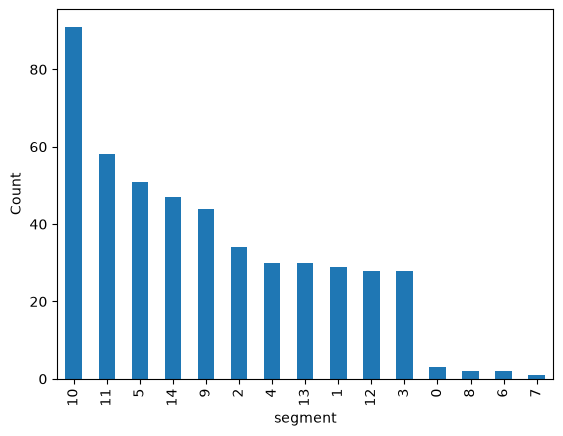

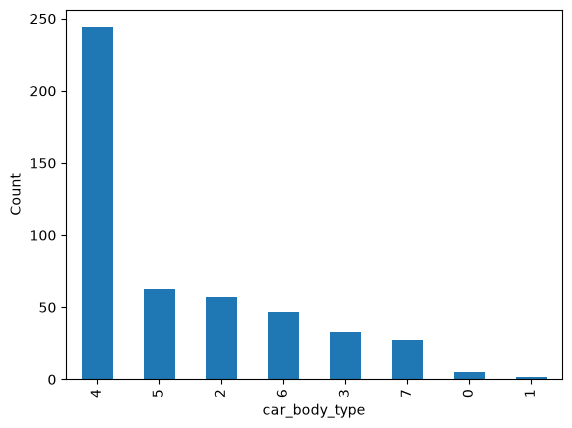

In [74]:
# 1. Distribution of categorical features

for col in categorical_cols:
    dataset[col].value_counts().plot(kind='bar')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

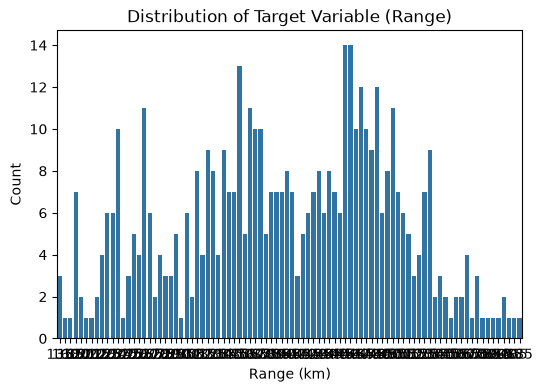

In [37]:
# 2. Distribution of the target variable

distribution = dataset['range_km'].value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=distribution.index, y=distribution.values)
plt.title('Distribution of Target Variable (Range)')
plt.xlabel('Range (km)')
plt.ylabel('Count')
plt.show()


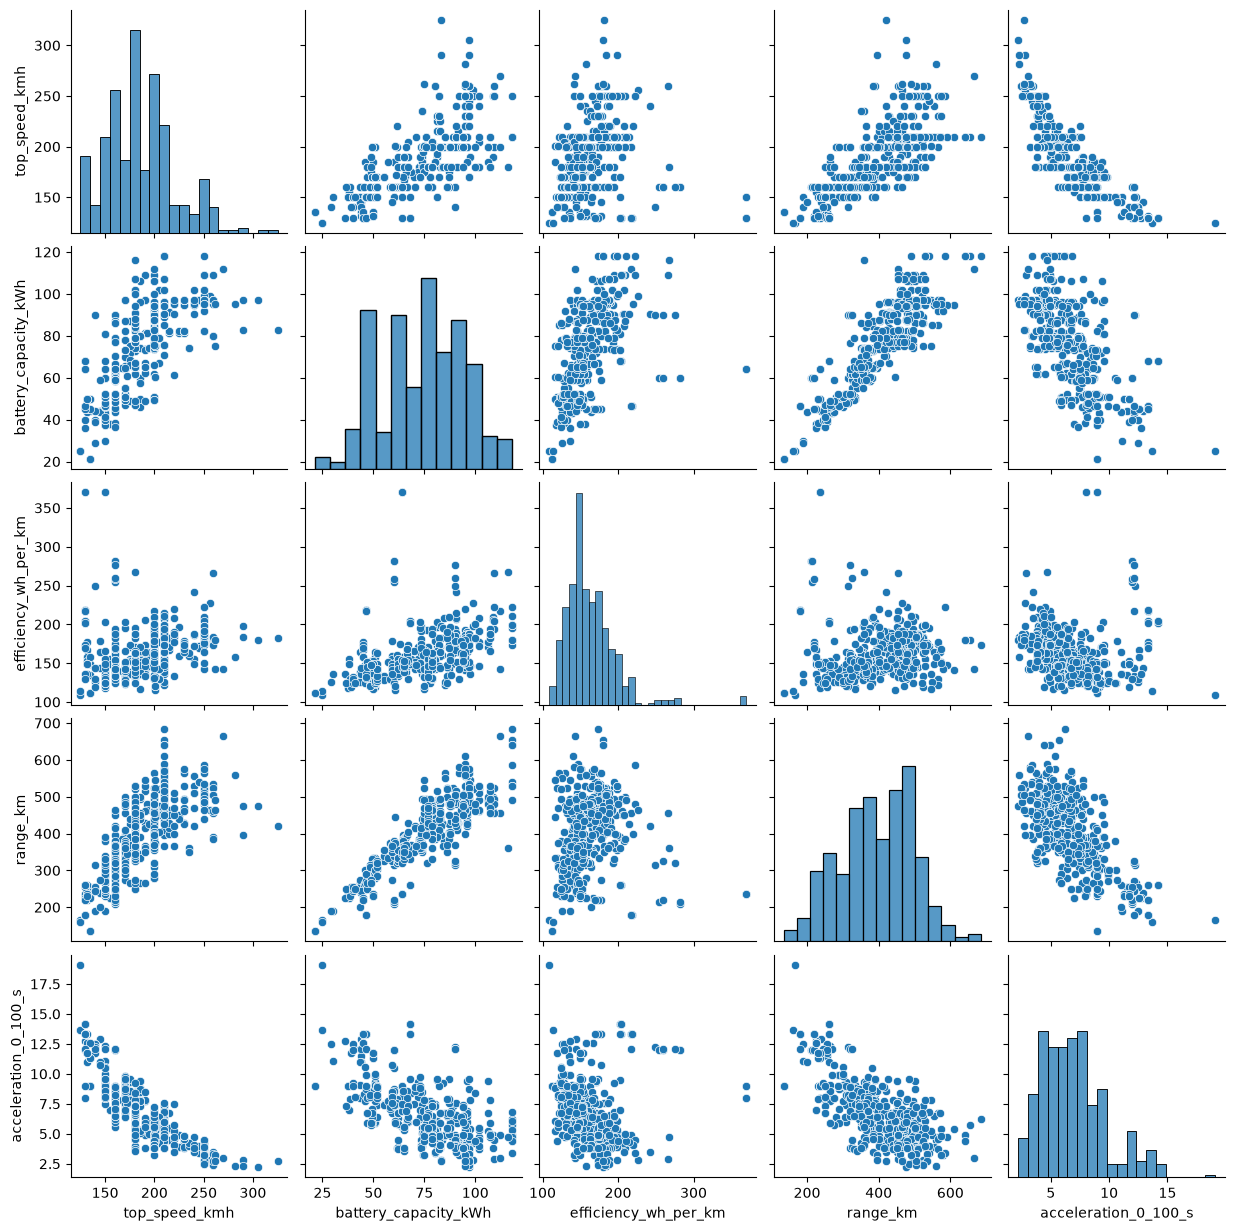

In [75]:
# 3. Pair plot for numerical variables
numerical_features = ['top_speed_kmh', 'battery_capacity_kWh', 'efficiency_wh_per_km',
                      'range_km', 'acceleration_0_100_s']


sns.pairplot(dataset[numerical_features])
plt.show()

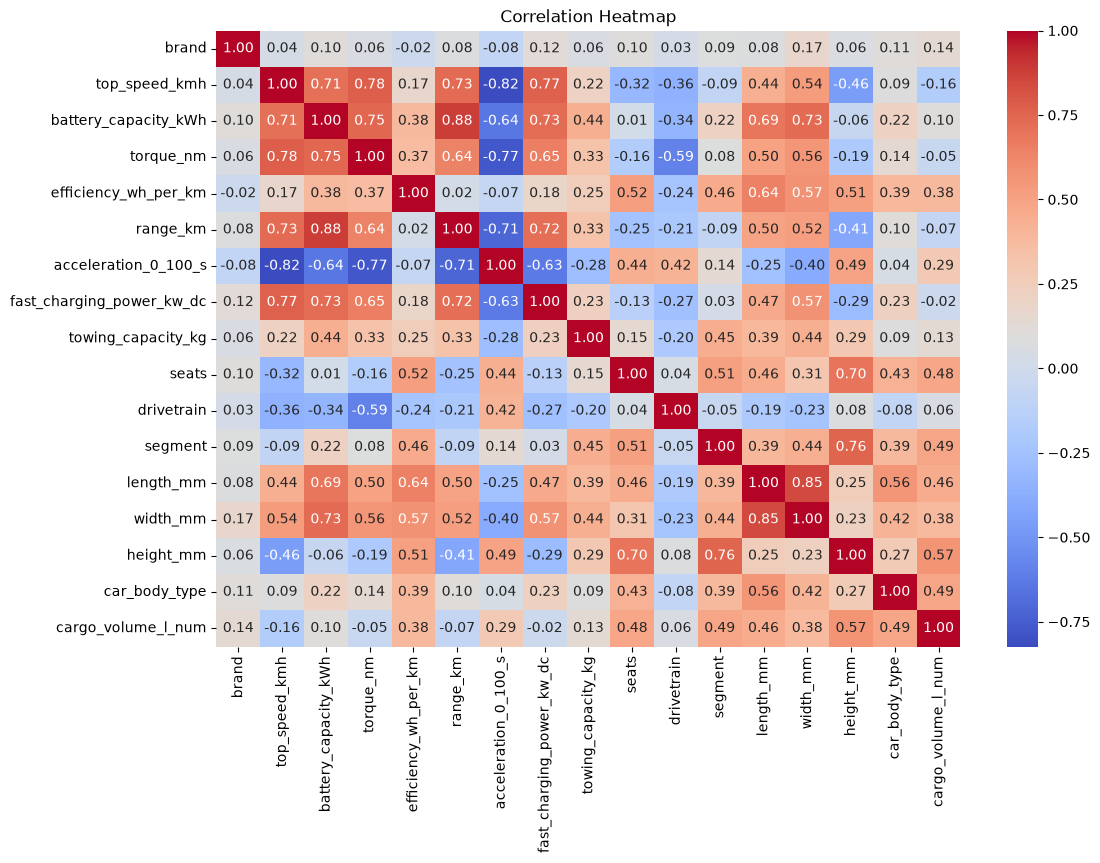

In [39]:
# 4. Correlation heatmap
plt.figure(figsize=(12, 8))
correlation = dataset.select_dtypes(include='number').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


### Defining Target Variable and Features

In [40]:
# Define the target variable (y) and features (X)
X = dataset.drop('range_km', axis=1)
y = dataset['range_km']


In [46]:
# Display the shapes to confirm
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (478, 16)
Target (y) shape: (478,)


In [47]:
# show the first few rows of X and y
print("First 5 rows of Features (X):")
print(X.head())

print("\nFirst 5 rows of Target (y):")
print(y.head())

First 5 rows of Features (X):
   brand  top_speed_kmh  battery_capacity_kWh  torque_nm  \
0      0            155                  37.8      235.0   
1      0            155                  37.8      235.0   
2      0            200                  50.8      345.0   
3      0            200                  50.8      345.0   
4      1            150                  60.0      310.0   

   efficiency_wh_per_km  acceleration_0_100_s  fast_charging_power_kw_dc  \
0                   156                   7.0                       67.0   
1                   149                   7.0                       67.0   
2                   158                   5.9                       79.0   
3                   158                   6.2                       79.0   
4                   156                   7.5                       78.0   

   towing_capacity_kg  seats  drivetrain  segment  length_mm  width_mm  \
0                 0.0      4           1        1       3673      1683   
1   

### Train-Test Split

In [72]:
# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (382, 16)
Testing data shape: (96, 16)


### Model Building

In [76]:
# Create Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


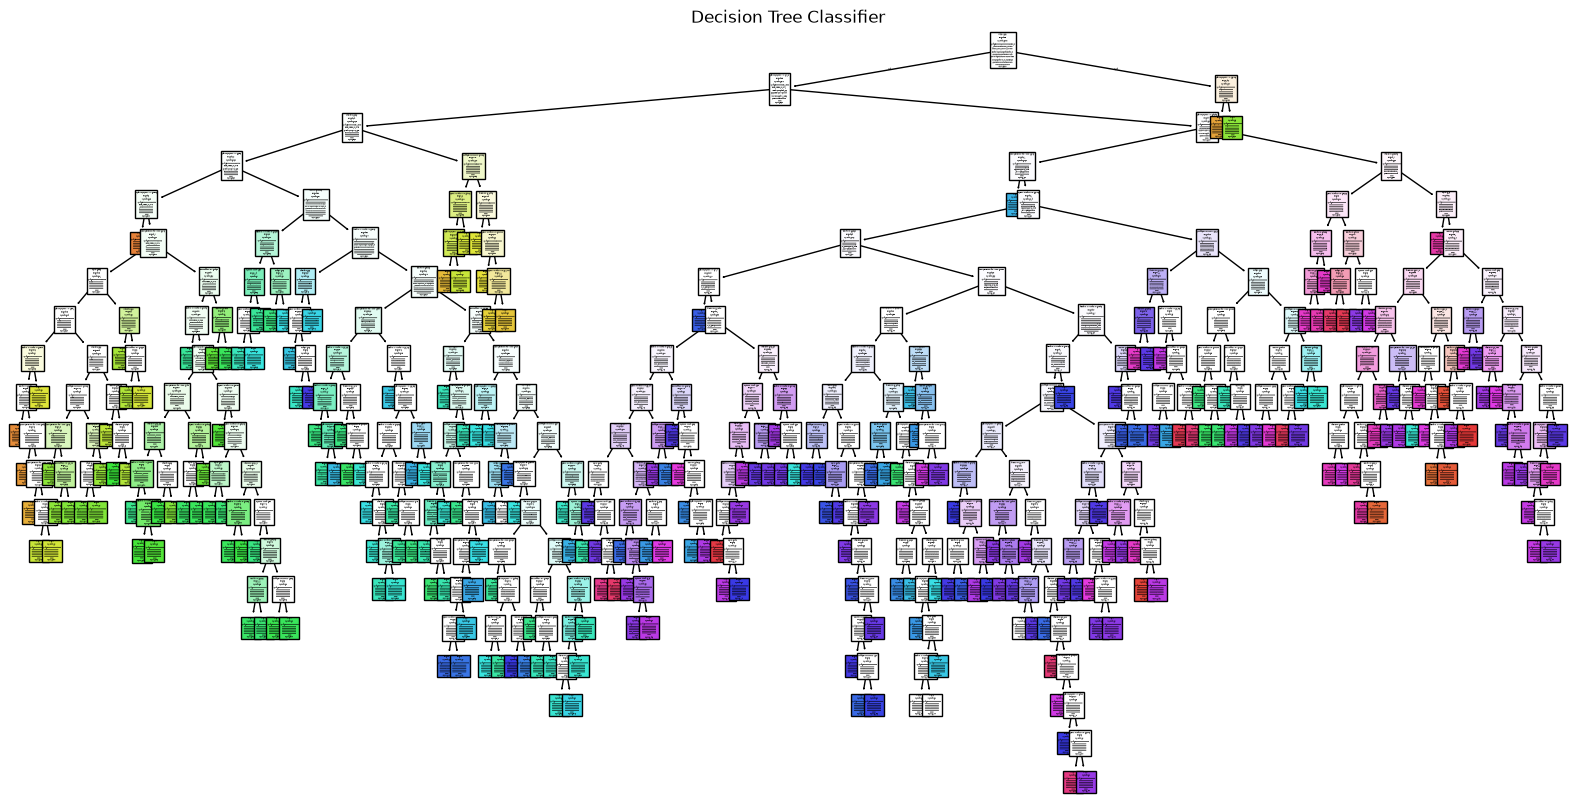

In [77]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True
)

plt.title("Decision Tree Classifier")
plt.show()

### Naive Bayes Classifier

In [66]:
from sklearn.naive_bayes import GaussianNB

# Create Naive Bayes model
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train, y_train)

# Make predictions
nb_pred = nb_model.predict(X_test)

print("Naive Bayes model trained successfully.")

Naive Bayes model trained successfully.


### K-Nearest Neighbors (KNN) Classifier

In [65]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train, y_train)

# Make predictions
knn_pred = knn_model.predict(X_test)

print("KNN model trained successfully.")

KNN model trained successfully.


### Support Vector Machine (SVM) Classifier

In [55]:
from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(kernel='rbf', random_state=42)

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
svm_pred = svm_model.predict(X_test)

print("SVM model trained successfully.")

SVM model trained successfully.


### Model Evaluation

In [80]:
# Calculate accuracy for each model

dt_accuracy = accuracy_score(y_test, dt_pred)
nb_accuracy = accuracy_score(y_test, nb_pred)
knn_accuracy = accuracy_score(y_test, knn_pred)
svm_accuracy = accuracy_score(y_test, svm_pred)

print("Model Accuracy:")
print(f"Decision Tree : {dt_accuracy:.4f}")
print(f"Naive Bayes   : {nb_accuracy:.4f}")
print(f"KNN           : {knn_accuracy:.4f}")
print(f"SVM           : {svm_accuracy:.4f}")


Model Accuracy:
Decision Tree : 0.2292
Naive Bayes   : 0.1771
KNN           : 0.1146
SVM           : 0.0104


### Confusion Matrix


In [81]:
# Dictionary of predictions

predictions = {
    'Decision Tree': dt_pred,
    'Naive Bayes': nb_pred,
    'KNN': knn_pred,
    'SVM': svm_pred
}

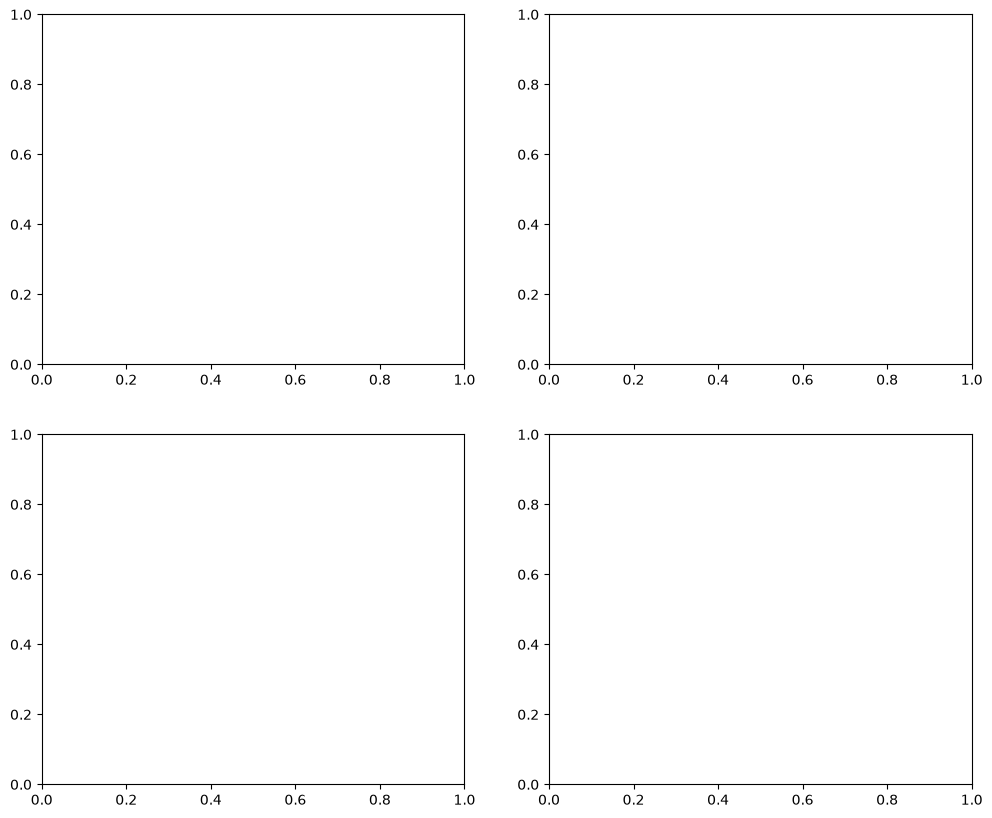

In [82]:
# Create subplots

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

In [70]:
# Plot confusion matrix for each model
for ax, (model, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(model)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

### Precision, Recall, and F1-Score

In [78]:
# Display classification report for each model
for model, pred in predictions.items():
    print(f"\n{model}")
    print(classification_report(y_test, pred))


Decision Tree
              precision    recall  f1-score   support

         180       1.00      1.00      1.00         1
         190       0.00      0.00      0.00         1
         220       1.00      1.00      1.00         1
         225       0.67      1.00      0.80         2
         230       0.29      1.00      0.44         2
         235       1.00      0.50      0.67         2
         240       0.00      0.00      0.00         0
         245       1.00      1.00      1.00         1
         250       0.00      0.00      0.00         2
         255       1.00      0.50      0.67         2
         260       1.00      1.00      1.00         3
         265       0.00      0.00      0.00         2
         270       0.00      0.00      0.00         1
         275       0.00      0.00      0.00         1
         280       0.00      0.00      0.00         0
         285       0.00      0.00      0.00         1
         290       0.00      0.00      0.00         1
         300

### Hypothesis test

In [85]:
from scipy import stats

In [ ]:
# test 1: 
# Pearson correlation

r,p=stats.pearsonr(dataset["battery_capacity_kWh"],dataset["range_km"])
print("H1 Pearson correlation:",r,"p-value:",p)

H1 Pearson correlation: 0.8804326848709593 p-value: 2.3071356412481812e-156


In [86]:
# test 2: 
# Welch t-test, SUV vs Sedan

suv=dataset.loc[dataset["car_body_type"]=="SUV","range_km"]
sedan=dataset.loc[dataset["car_body_type"]=="Sedan","range_km"]
t,p=stats.ttest_ind(suv,sedan,equal_var=False)
print("H2 Welch t-test:",t,"p-value:",p)

H2 Welch t-test: nan p-value: nan
